**Trabalho Final - Redes Neurais**  
Equipe: Leo, Alex, João, Yan e Karine  
Parte: Preparação dos dados (Leo)

Este notebook prepara as avaliações do B2W para os modelos do grupo. Os passos são: carregar o dataset, verificar os dados, limpar, criar os rótulos (positiva ou negativa), ver o equilíbrio entre as classes, dividir em treino, validação e teste e salvar os arquivos.

**Fonte:** [B2W-Reviews01 (B2W Digital / Americanas)](https://github.com/americanas-tech/b2w-reviews01)  
**Arquivo utilizado:** B2W-Reviews01.csv  
**Licença:** CC BY-NC-SA 4.0, conforme o README do repositório oficial.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

**Carregamento**

Se o `B2W-Reviews01.csv` foi enviado para o Colab, ele é lido direto. Se não, o arquivo é baixado do GitHub oficial.

In [2]:
arquivo_local = "B2W-Reviews01.csv"
url = "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv"

if os.path.exists(arquivo_local):
    df = pd.read_csv(arquivo_local, low_memory=False)
else:
    df = pd.read_csv(url, low_memory=False)

**Verificação dos dados**

Tamanho da tabela, primeiras linhas, valores ausentes por coluna, textos repetidos e quantidade de avaliações por nota.

In [3]:
df.shape

(132373, 14)

In [4]:
df.head()

,submission_date,reviewer_id,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,overall_rating,recommend_to_a_friend,review_text,reviewer_birth_year,reviewer_gender,reviewer_state
0,2018-01-01 00:11:28,d0fb1ca69422530334178f5c8624aa7a99da47907c44de...,132532965,Notebook Asus Vivobook Max X541NA-GO472T Intel...,NaN,Informática,Notebook,Bom,4,Yes,Estou contente com a compra entrega rápida o ú...,1958.0,F,RJ
1,2018-01-01 00:13:48,014d6dc5a10aed1ff1e6f349fb2b059a2d3de511c7538a...,22562178,Copo Acrílico Com Canudo 500ml Rocie,NaN,Utilidades Domésticas,"Copos, Taças e Canecas","Preço imbatível, ótima qualidade",4,Yes,"Por apenas R$1994.20,eu consegui comprar esse ...",1996.0,M,SC
2,2018-01-01 00:26:02,44f2c8edd93471926fff601274b8b2b5c4824e386ae4f2...,113022329,Panela de Pressão Elétrica Philips Walita Dail...,philips walita,Eletroportáteis,Panela Elétrica,ATENDE TODAS AS EXPECTATIVA.,4,Yes,SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANEL...,1984.0,M,SP
3,2018-01-01 00:35:54,ce741665c1764ab2d77539e18d0e4f66dde6213c9f0863...,113851581,Betoneira Columbus - Roma Brinquedos,roma jensen,Brinquedos,Veículos de Brinquedo,presente mais que desejado,4,Yes,MEU FILHO AMOU! PARECE DE VERDADE COM TANTOS D...,1985.0,F,SP
4,2018-01-01 01:00:28,7d7b6b18dda804a897359276cef0ca252f9932bf4b5c8e...,131788803,"Smart TV LED 43"" LG 43UJ6525 Ultra HD 4K com C...",lg,TV e Home Theater,TV,"Sem duvidas, excelente",5,Yes,"A entrega foi no prazo, as americanas estão de...",1994.0,M,MG


In [5]:
df.isnull().sum()

submission_date              0
reviewer_id                  0
product_id                   0
product_name                84
product_brand            91391
site_category_lv1            6
site_category_lv2         4013
review_title               302
overall_rating               0
recommend_to_a_friend       18
review_text               3275
reviewer_birth_year       5984
reviewer_gender           4136
reviewer_state            3991
dtype: int64

In [6]:
df["review_text"].dropna().duplicated().sum()

np.int64(2374)

In [7]:
df["overall_rating"].value_counts().sort_index()

overall_rating
1    27369
2     8389
3    16315
4    32345
5    47955
Name: count, dtype: int64

**Seleção das colunas**

Das 14 colunas, ficam só `review_text` (o texto, que é a entrada do modelo) e `overall_rating` (a nota de 1 a 5, usada para criar o rótulo). As colunas com dados pessoais (id, idade, gênero e estado de quem avaliou) não são usadas.

In [8]:
total_original = len(df)
df = df[["review_text", "overall_rating"]].copy()
df.columns = ["texto", "nota"]
df.head()

,texto,nota
0,Estou contente com a compra entrega rápida o ú...,4
1,"Por apenas R$1994.20,eu consegui comprar esse ...",4
2,SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANEL...,4
3,MEU FILHO AMOU! PARECE DE VERDADE COM TANTOS D...,4
4,"A entrega foi no prazo, as americanas estão de...",5


**Limpeza**

1. Remove as linhas sem texto ou sem nota.
2. Remove espaços sobrando e textos com menos de 3 caracteres, e mantém só notas de 1 a 5.
3. Remove os duplicados. Para isso é criada uma versão do texto em minúsculo e sem pontuação (`texto_norm`), assim "Muito bom!" e "muito bom" contam como iguais. Essa coluna só serve para comparar e é apagada depois. Remover duplicados evita que a mesma avaliação caia no treino e no teste ao mesmo tempo.

In [9]:
df = df.dropna(subset=["texto", "nota"])
apos_vazios = len(df)

In [10]:
df["texto"] = df["texto"].astype(str).str.strip()
df = df[df["texto"].str.len() >= 3]
df["nota"] = pd.to_numeric(df["nota"], errors="coerce")
df = df[df["nota"].between(1, 5)]
apos_invalidos = len(df)

In [11]:
df["texto_norm"] = df["texto"].str.lower()
df["texto_norm"] = df["texto_norm"].str.replace(r"[^\w\s]", "", regex=True)
df["texto_norm"] = df["texto_norm"].str.split().str.join(" ")

In [12]:
df = df[df["texto_norm"].str.len() >= 3]
df = df.drop_duplicates(subset="texto_norm")
df = df.drop(columns="texto_norm")
apos_duplicados = len(df)

In [13]:
print("Original:", total_original)
print("Sem vazios:", apos_vazios)
print("Sem inválidos:", apos_invalidos)
print("Sem duplicados:", apos_duplicados)

Original: 132373
Sem vazios: 129098
Sem inválidos: 129098
Sem duplicados: 126301


**Rótulos**

Notas 1 e 2 viram negativa (0), notas 4 e 5 viram positiva (1) e as notas 3 são descartadas, porque são neutras e misturam elogio com reclamação. O rótulo é 0 ou 1 porque o modelo trabalha com números. A coluna `sentimento` serve só para leitura.

In [14]:
(df["nota"] == 3).sum()

np.int64(15793)

In [15]:
df = df[df["nota"] != 3].copy()
df["rotulo"] = (df["nota"] >= 4).astype(int)
df["sentimento"] = df["rotulo"].map({1: "positiva", 0: "negativa"})
df.sample(5, random_state=1)

,texto,nota,rotulo,sentimento
40110,O produto é fácil para transportar em uma mala...,4,1,positiva
31855,"Adorei ,ele é bom e bonito,a única coisa que n...",4,1,positiva
41712,"PRODUTO DE QUALIDADE, ESTOU MUITO SATISFEITA. ...",5,1,positiva
90813,"Ótimo produto, imagem perfeita, sem nenhuma...",5,1,positiva
51312,"Ótima fixação, essência parecida com o 212 VIP...",5,1,positiva


In [16]:
df["sentimento"].value_counts()

sentimento
positiva    77936
negativa    32572
Name: count, dtype: int64

In [17]:
(df["sentimento"].value_counts(normalize=True) * 100).round(1)

sentimento
positiva    70.5
negativa    29.5
Name: proportion, dtype: float64

**Gráfico 1: Distribuição das classes**

São 77.936 avaliações positivas (70,5%) e 32.572 negativas (29,5%), cerca de 2,4 positivas para cada negativa. O dataset está desbalanceado: um modelo que respondesse sempre "positiva" já acertaria 70,5%, por isso a comparação dos modelos vai usar principalmente o F1-score. Nenhum dado foi removido para equilibrar, porque o desbalanceamento não é extremo.

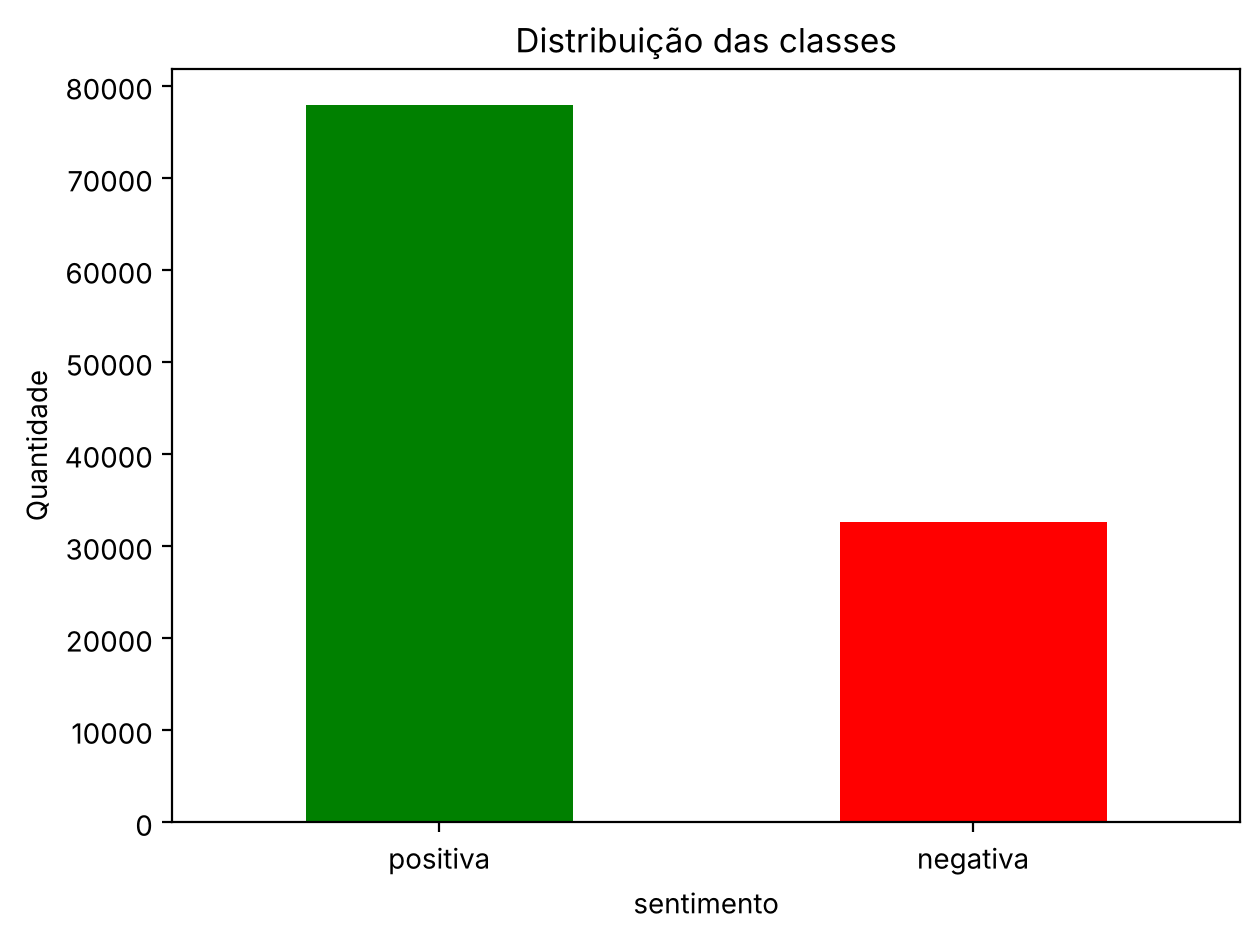

In [18]:
contagem = df["sentimento"].value_counts()
contagem.plot(kind="bar", color=["green", "red"], title="Distribuição das classes")
plt.ylabel("Quantidade")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("distribuicao_classes.png")
plt.show()

**Divisão em treino, validação e teste (70 / 15 / 15)**

Primeiro separa 70% para treino e 30% para o resto, depois divide esses 30% ao meio. O `stratify` mantém a mesma proporção de positivas nos três conjuntos, e o `random_state=42` faz a divisão sair sempre igual, para todo o grupo usar os mesmos dados.

In [19]:
treino, temp = train_test_split(df, test_size=0.30, stratify=df["rotulo"], random_state=42)
validacao, teste = train_test_split(temp, test_size=0.50, stratify=temp["rotulo"], random_state=42)

In [20]:
len(treino), len(validacao), len(teste)

(77355, 16576, 16577)

In [21]:
treino["rotulo"].mean(), validacao["rotulo"].mean(), teste["rotulo"].mean()

(np.float64(0.7052549932131084),
 np.float64(0.7052364864864865),
 np.float64(0.7052542679616336))

**Verificação de vazamento**

Conta quantos textos aparecem em mais de um conjunto. O resultado precisa ser 0, senão o modelo seria testado com avaliações que já viu no treino.

In [22]:
print("Treino e teste:", treino["texto"].isin(teste["texto"]).sum())
print("Treino e validação:", treino["texto"].isin(validacao["texto"]).sum())
print("Validação e teste:", validacao["texto"].isin(teste["texto"]).sum())

Treino e teste: 0
Treino e validação: 0
Validação e teste: 0


**Arquivos gerados**

| Arquivo | Linhas | O que é | Quem usa |
|---|---|---|---|
| `treino.csv` | 77.355 | Avaliações que os modelos usam para aprender | Baseline (TF-IDF + regressão logística) e BERTimbau |
| `validacao.csv` | 16.576 | Avaliações para acompanhar o desempenho durante o treino e ajustar parâmetros | BERTimbau |
| `teste.csv` | 16.577 | Avaliações que nenhum modelo vê no treino, usadas só no final para medir o desempenho | Avaliação final dos dois modelos |
| `distribuicao_classes.png` | — | Gráfico da distribuição das classes | Slides |

Os três CSVs têm as mesmas colunas: `texto` (a avaliação), `nota` (de 1 a 5), `rotulo` (1 = positiva, 0 = negativa) e `sentimento` (o rótulo escrito por extenso).

In [23]:
cols = ["texto", "nota", "rotulo", "sentimento"]
treino[cols].to_csv("treino.csv", index=False)
validacao[cols].to_csv("validacao.csv", index=False)
teste[cols].to_csv("teste.csv", index=False)

In [ ]:
from google.colab import files
for f in ["treino.csv", "validacao.csv", "teste.csv", "distribuicao_classes.png"]:
    files.download(f)